Import libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

from sklearn.calibration import calibration_curve

import joblib
import shap
import sklearn

RANDOM_STATE = 42

Load the dataset

In [2]:
df = pd.read_csv("../data/customer_churn_advanced_dataset.csv")

df.head()

,customer_id,age,tenure_months,contract_type,internet_service,region,monthly_charges,total_charges,payment_method,paperless_billing,dependents,support_plan,tech_support,complaints_last_12m,late_payments_last_12m,satisfaction_score,monthly_usage_gb,discount_pct,senior_citizen,churn
0,CUST100001,23,64,One year,Fiber optic,Eastern,48.36,3082.83,Mailed check,No,No,No,No,0,0,6.2,16.4,5.61,0,1
1,CUST100002,62,35,One year,DSL,Central,51.34,1585.19,Electronic check,Yes,No,Yes,No,1,1,7.4,38.1,0.00,0,1
2,CUST100003,55,71,Month-to-month,DSL,North Central,130.98,8564.89,Bank transfer,No,No,No,No,0,1,8.2,NaN,22.92,0,1
3,CUST100004,43,55,Month-to-month,Fiber optic,Western,115.24,6390.85,Credit card,Yes,No,No,No,0,1,9.8,70.1,9.66,0,1
4,CUST100005,43,47,Month-to-month,Fiber optic,Sabaragamuwa,62.12,2540.63,Electronic check,Yes,No,No,No,3,0,8.5,144.2,11.20,0,1


In [3]:
df.shape

(1200, 20)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             1200 non-null   str    
 1   age                     1200 non-null   int64  
 2   tenure_months           1200 non-null   int64  
 3   contract_type           1200 non-null   str    
 4   internet_service        1200 non-null   str    
 5   region                  1200 non-null   str    
 6   monthly_charges         1170 non-null   float64
 7   total_charges           1176 non-null   float64
 8   payment_method          1200 non-null   str    
 9   paperless_billing       1200 non-null   str    
 10  dependents              1200 non-null   str    
 11  support_plan            1200 non-null   str    
 12  tech_support            1200 non-null   str    
 13  complaints_last_12m     1200 non-null   int64  
 14  late_payments_last_12m  1200 non-null   int64  
 15

## Data Audit

Check data types

In [5]:
df.dtypes

customer_id                   str
age                         int64
tenure_months               int64
contract_type                 str
internet_service              str
region                        str
monthly_charges           float64
total_charges             float64
payment_method                str
paperless_billing             str
dependents                    str
support_plan                  str
tech_support                  str
complaints_last_12m         int64
late_payments_last_12m      int64
satisfaction_score        float64
monthly_usage_gb          float64
discount_pct              float64
senior_citizen              int64
churn                       int64
dtype: object

In [6]:
numeric_cols = df.select_dtypes(include=np.number).columns
categorical_cols = df.select_dtypes(include="object").columns

print("Numeric:", numeric_cols)
print("Categorical:", categorical_cols)

Numeric: Index(['age', 'tenure_months', 'monthly_charges', 'total_charges',
       'complaints_last_12m', 'late_payments_last_12m', 'satisfaction_score',
       'monthly_usage_gb', 'discount_pct', 'senior_citizen', 'churn'],
      dtype='str')
Categorical: Index(['customer_id', 'contract_type', 'internet_service', 'region',
       'payment_method', 'paperless_billing', 'dependents', 'support_plan',
       'tech_support'],
      dtype='str')


C:\Users\nimeshi\AppData\Local\Temp\ipykernel_21604\2369420661.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns


Check missing values

In [7]:
missing = df.isnull().sum()

missing_df = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": missing / len(df) * 100
})

missing_df.sort_values(
    "Missing_Count",
    ascending=False
)

,Missing_Count,Missing_Percentage
satisfaction_score,48,4.0
monthly_usage_gb,36,3.0
monthly_charges,30,2.5
total_charges,24,2.0
contract_type,0,0.0
tenure_months,0,0.0
age,0,0.0
customer_id,0,0.0
payment_method,0,0.0
paperless_billing,0,0.0


Check duplicates

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["customer_id"].duplicated().sum()

np.int64(0)

Customer ID handling

In [10]:
X = df.drop(columns=["churn", "customer_id"])
y = df["churn"]

In [11]:
X = df.drop(columns=["churn", "customer_id"])
y = df["churn"]

Check invalid values

In [12]:
df.describe()

,age,tenure_months,monthly_charges,total_charges,complaints_last_12m,late_payments_last_12m,satisfaction_score,monthly_usage_gb,discount_pct,senior_citizen,churn
count,1200.000000,1200.000000,1170.000000,1176.000000,1200.000000,1200.000000,1152.000000,1164.000000,1200.000000,1200.000000,1200.000000
mean,46.746667,36.265833,71.429769,2568.007194,0.714167,0.837500,6.744097,66.925773,9.163592,0.171667,0.863333
std,16.666702,20.917372,25.823951,1807.259488,0.846402,0.886989,1.784122,39.596157,6.608772,0.377248,0.343638
min,18.000000,1.000000,20.000000,22.730000,0.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000
25%,32.000000,18.000000,54.445000,1119.230000,0.000000,0.000000,5.600000,41.175000,3.577500,0.000000,1.000000
50%,47.000000,35.000000,71.820000,2244.460000,1.000000,1.000000,6.750000,66.400000,8.715000,0.000000,1.000000
75%,61.000000,54.000000,86.995000,3752.027500,1.000000,1.000000,8.000000,89.325000,13.695000,0.000000,1.000000
max,75.000000,72.000000,235.010000,8853.760000,5.000000,4.000000,10.000000,466.900000,32.890000,1.000000,1.000000


Outlier analysis

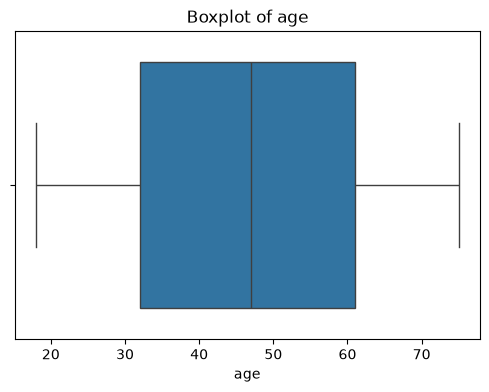

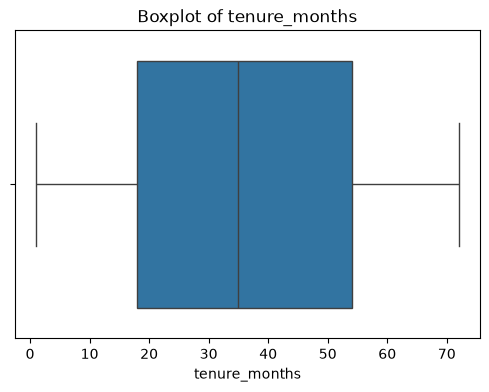

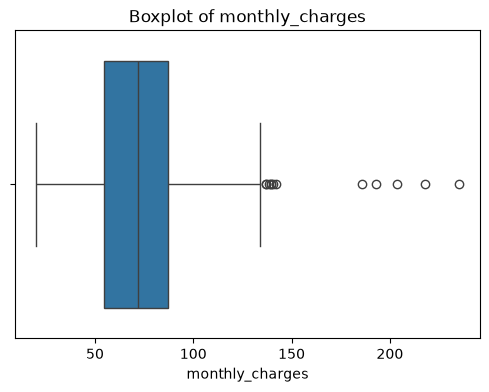

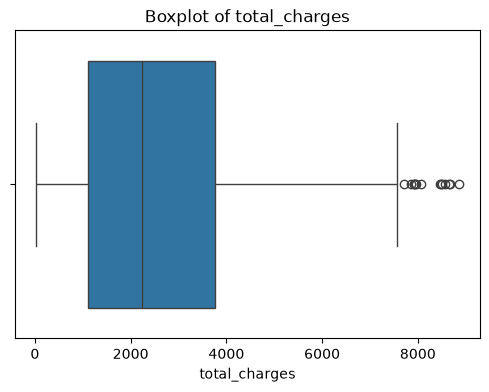

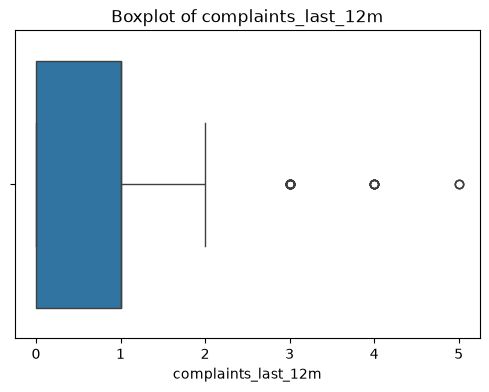

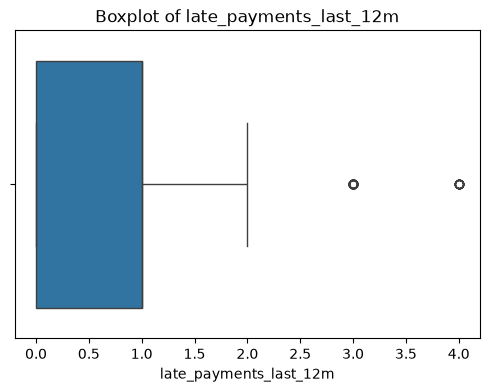

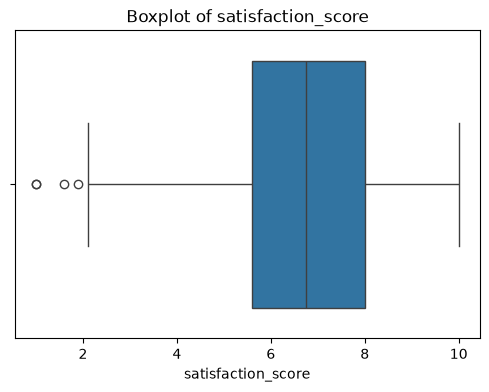

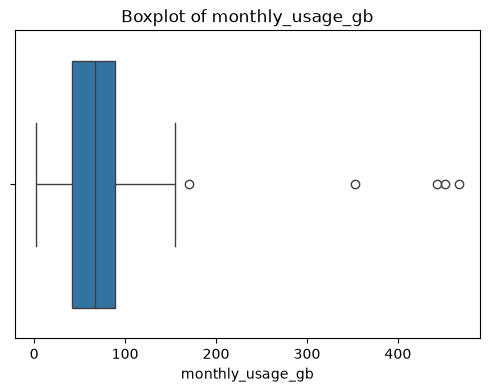

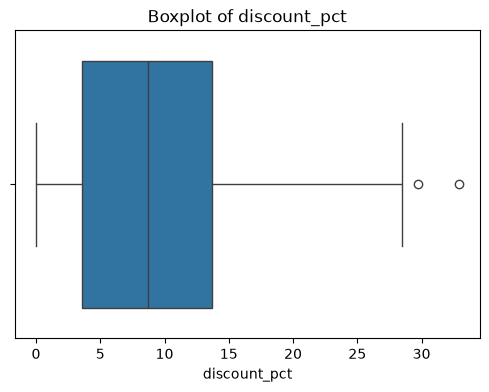

In [13]:
numeric_features = [
    "age",
    "tenure_months",
    "monthly_charges",
    "total_charges",
    "complaints_last_12m",
    "late_payments_last_12m",
    "satisfaction_score",
    "monthly_usage_gb",
    "discount_pct"
]

for col in numeric_features:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

Target distribution

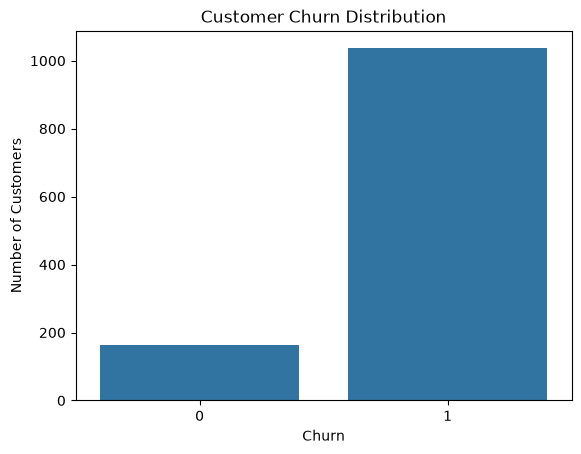

In [14]:
sns.countplot(x="churn", data=df)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

In [15]:
df["churn"].value_counts(normalize=True) * 100

churn
1    86.333333
0    13.666667
Name: proportion, dtype: float64

## Exploratory Data Analysis

Visualization 1 — Contract type vs churn

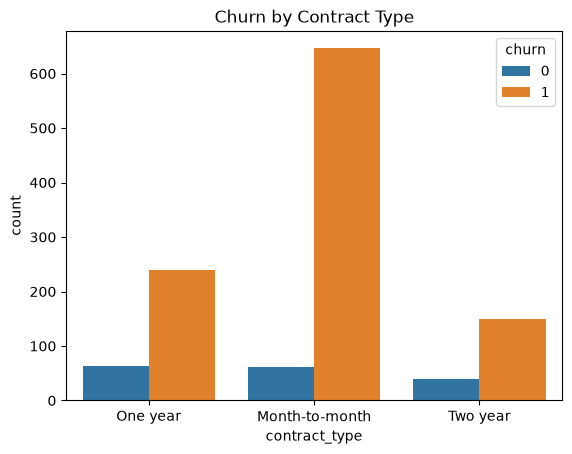

In [16]:
sns.countplot(
    data=df,
    x="contract_type",
    hue="churn"
)

plt.title("Churn by Contract Type")
plt.show()

Visualization 2 — Tenure vs churn

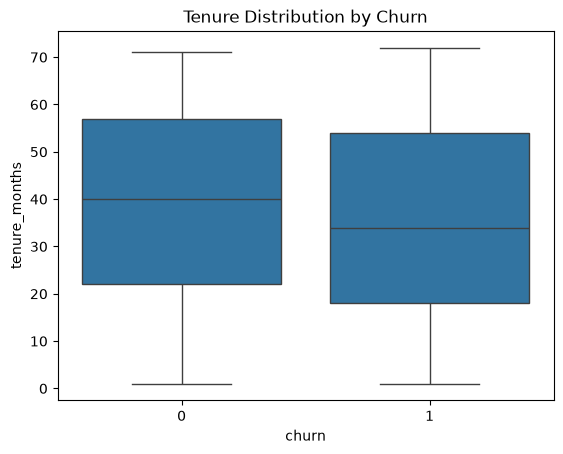

In [17]:
sns.boxplot(
    data=df,
    x="churn",
    y="tenure_months"
)

plt.title("Tenure Distribution by Churn")
plt.show()

Visualization 3 — Monthly charges vs churn

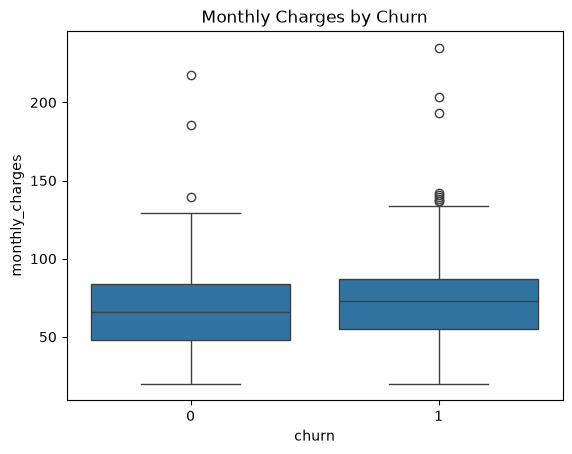

In [18]:
sns.boxplot(
    data=df,
    x="churn",
    y="monthly_charges"
)

plt.title("Monthly Charges by Churn")
plt.show()

Visualization 4 — Satisfaction vs churn

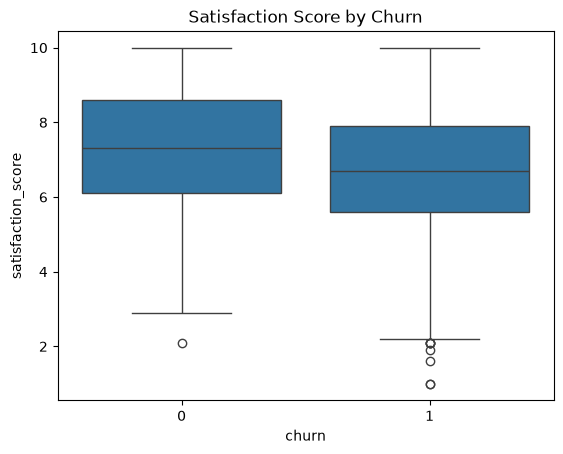

In [19]:
sns.boxplot(
    data=df,
    x="churn",
    y="satisfaction_score"
)

plt.title("Satisfaction Score by Churn")
plt.show()

Visualization 5 — Payment method

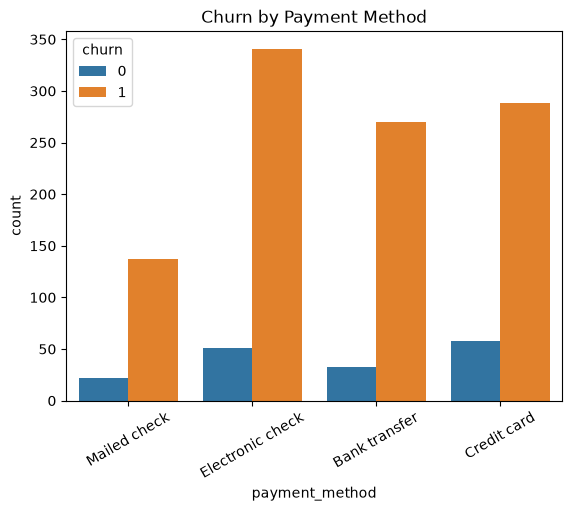

In [20]:
sns.countplot(
    data=df,
    x="payment_method",
    hue="churn"
)

plt.xticks(rotation=30)
plt.title("Churn by Payment Method")
plt.show()

Visualization 6 — Complaints vs churn

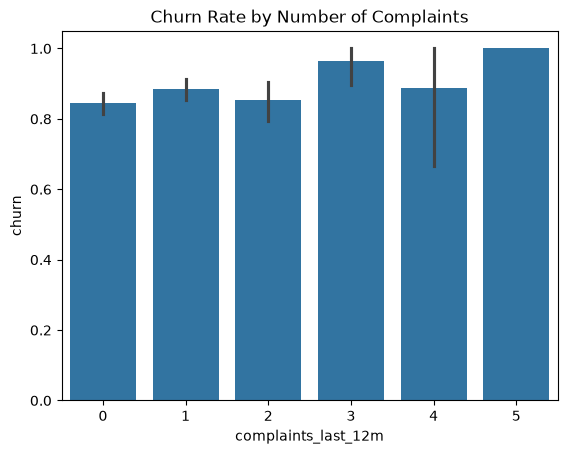

In [21]:
sns.barplot(
    data=df,
    x="complaints_last_12m",
    y="churn"
)

plt.title("Churn Rate by Number of Complaints")
plt.show()

Visualization 7 — Late payments vs churn

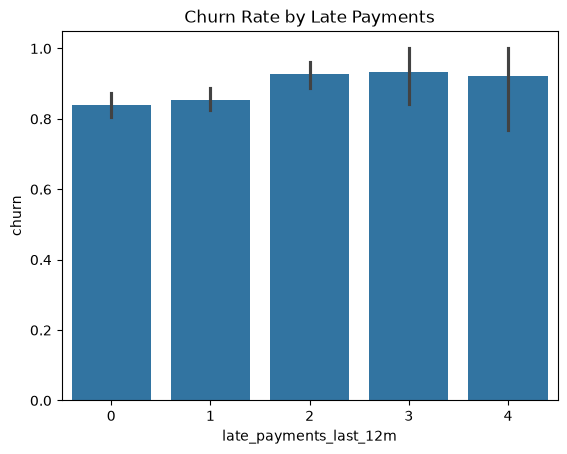

In [22]:
sns.barplot(
    data=df,
    x="late_payments_last_12m",
    y="churn"
)

plt.title("Churn Rate by Late Payments")
plt.show()

Investigate interactions

Contract × satisfaction

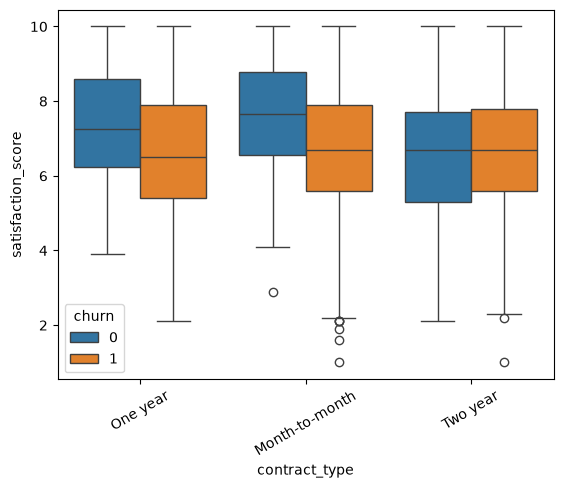

In [23]:
sns.boxplot(
    data=df,
    x="contract_type",
    y="satisfaction_score",
    hue="churn"
)
plt.xticks(rotation=30)
plt.show()

Contract × tenure

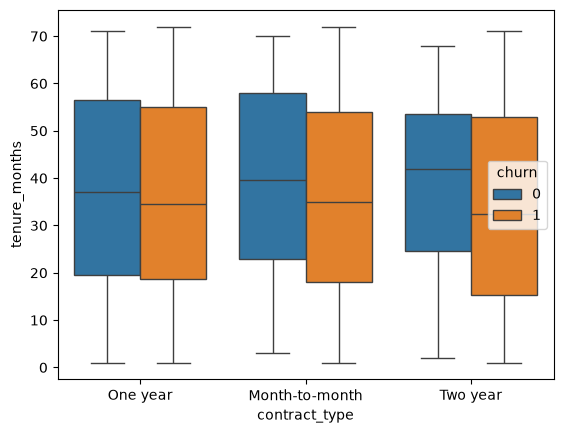

In [24]:
sns.boxplot(
    data=df,
    x="contract_type",
    y="tenure_months",
    hue="churn"
)
plt.show()

Payment × contract

In [25]:
pd.crosstab(
    df["payment_method"],
    df["contract_type"],
    values=df["churn"],
    aggfunc="mean"
)

contract_type,Month-to-month,One year,Two year
payment_method,,,
Bank transfer,0.935829,0.797297,0.857143
Credit card,0.879397,0.763441,0.777778
Electronic check,0.929825,0.796117,0.770492
Mailed check,0.893617,0.848485,0.781250


Feature Engineering

Feature 1 — Charge per tenure

In [26]:
df["charge_per_tenure"] = (
    df["total_charges"] /
    df["tenure_months"].replace(0, np.nan)
)

Feature 2 — Payment risk

In [27]:
df["payment_risk"] = (
    df["late_payments_last_12m"] +
    df["complaints_last_12m"]
)

Feature 3 — Complaint intensity

In [28]:
df["complaint_intensity"] = (
    df["complaints_last_12m"] /
    (df["tenure_months"] + 1)
)

Feature 4 — Late payment indicator

In [29]:
df["has_late_payment"] = (
    df["late_payments_last_12m"] > 0
).astype(int)

Feature 5 — Complaint indicator

In [30]:
df["has_complaint"] = (
    df["complaints_last_12m"] > 0
).astype(int)

Feature 6 — Low satisfaction

In [31]:
df["low_satisfaction"] = (
    df["satisfaction_score"] < 6
).astype(int)

Feature 6 — Low satisfaction

In [32]:
df["low_satisfaction"] = (
    df["satisfaction_score"] < 6
).astype(int)

Feature 7 — High usage

In [33]:
usage_threshold = df["monthly_usage_gb"].quantile(0.75)

df["high_usage"] = (
    df["monthly_usage_gb"] > usage_threshold
).astype(int)

Leakage prevention

Train/Test split

In [34]:
X = df.drop(columns=["churn", "customer_id"])
y = df["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

## Create preprocessing pipeline

In [35]:
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include="object"
).columns.tolist()

C:\Users\nimeshi\AppData\Local\Temp\ipykernel_21604\2828727332.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


Numeric pipeline:

In [36]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

Categorical:

In [37]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

Combine:

In [38]:
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

## Model 1 — Logistic Regression

In [39]:
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

In [40]:
logistic_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](25,)","['age','tenure_months','contract_type',...,'has_complaint', 'low_satisfaction','high_usage']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,25
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder=

Model 2 — Random Forest

In [41]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42
    ))
])

Baseline model comparison

In [45]:

from sklearn.base import clone
import pandas as pd

# Train both models
logistic_pipeline.fit(X_train, y_train)
rf_pipeline.fit(X_train, y_train)

# Evaluate both models
logistic_results = evaluate_model(
    logistic_pipeline, X_test, y_test
)

rf_results = evaluate_model(
    rf_pipeline, X_test, y_test
)

# Compare model performance
comparison_df = pd.DataFrame({
    "Logistic Regression": logistic_results,
    "Random Forest": rf_results
})

print("\n========== MODEL COMPARISON ==========")
print(comparison_df.round(4).to_string())

# Identify the best model based on ROC-AUC
best_model_name = comparison_df.loc["ROC-AUC"].idxmax()

print("\nBest Model based on ROC-AUC:", best_model_name)


===== Model Evaluation Results =====
--------------------------------------
Accuracy    : 0.8917
Precision   : 0.9022
Recall      : 0.9807
F1          : 0.9398
ROC-AUC     : 0.9166
PR-AUC      : 0.9832
===== Model Evaluation Results =====
--------------------------------------
Accuracy    : 0.8625
Precision   : 0.8655
Recall      : 0.9952
F1          : 0.9258
ROC-AUC     : 0.8819
PR-AUC      : 0.9687

========== MODEL COMPARISON ==========
           Logistic Regression  Random Forest
Accuracy                0.8917         0.8625
Precision               0.9022         0.8655
Recall                  0.9807         0.9952
F1                      0.9398         0.9258
ROC-AUC                 0.9166         0.8819
PR-AUC                  0.9832         0.9687

Best Model based on ROC-AUC: Logistic Regression


Class imbalance handling

For Logistic Regression:

In [46]:
class_weight="balanced"

Hyperparameter tuning

In [47]:
StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

In [48]:
param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 5, 10, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__class_weight": [None, "balanced"]
}

In [49]:
search = RandomizedSearchCV(
    rf_pipeline,
    param_distributions=param_grid,
    n_iter=20,
    scoring="average_precision",
    cv=5,
    random_state=42,
    n_jobs=-1
)

In [54]:

from sklearn.model_selection import RandomizedSearchCV

search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=5,
    cv=3,
    scoring="roc_auc",
    n_jobs=1,
    random_state=42,
    verbose=1,
    error_score="raise"
)


Final test set

In [55]:
search.fit(X_train, y_train)

best_model = search.best_estimator_

print("Best Parameters:", search.best_params_)
print("Best CV ROC-AUC:", round(search.best_score_, 4))

Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best Parameters: {'model__n_estimators': 100, 'model__min_samples_split': 10, 'model__min_samples_leaf': 4, 'model__max_depth': 20, 'model__class_weight': 'balanced'}
Best CV ROC-AUC: 0.8755


In [56]:
results = evaluate_model(best_model, X_test, y_test)

===== Model Evaluation Results =====
--------------------------------------
Accuracy    : 0.8792
Precision   : 0.9684
Recall      : 0.8889
F1          : 0.9270
ROC-AUC     : 0.9104
PR-AUC      : 0.9835
